# Mega-Sena: dá para vencer o acaso?

Este notebook percorre a análise de ponta a ponta usando as funções do pacote `mega_sena`:

1. **Dados**: carga e estrutura do histórico
2. **Análise exploratória**: frequências, pares e ímpares, quadrantes
3. **Testes de hipótese**: os sorteios são uniformes?
4. **Backtest**: alguma estratégia baseada no histórico vence o acaso?

Todo o código pesado está no pacote; aqui ficam só as chamadas e a interpretação. Para atualizar os
dados com os concursos mais recentes, rode `python -m mega_sena.dataset` antes de abrir o
notebook.

## Configuração

Altere os parâmetros abaixo e rode o notebook de novo para ver o efeito.

In [1]:
N_SIMS = 2000  # simulações de Monte Carlo (testes e distribuição nula do backtest)
HOT_WINDOW = 50  # janela, em concursos, da estratégia "quentes recentes"
START = 100  # concursos usados só como histórico inicial no backtest
SEED = 42  # semente: mesmos parâmetros, mesmos resultados

In [2]:
%load_ext autoreload
%autoreload 2

from loguru import logger
import pandas as pd

logger.disable("mega_sena")  # os logs do pacote são para a linha de comando, não para o notebook

from mega_sena import plots
from mega_sena.config import PROCESSED_RESULTS_FILE
from mega_sena.dataset import load_processed, to_long
from mega_sena.features import build_features, draws_matrix, number_frequencies
from mega_sena.hypothesis import run_all_tests
from mega_sena.modeling.backtest import (
    cold_strategy,
    compare_strategies,
    hot_strategy,
    random_strategy,
)

plots.set_style()
pd.set_option("display.float_format", "{:.4f}".format)

if not PROCESSED_RESULTS_FILE.exists():
    raise FileNotFoundError("Rode `python -m mega_sena.dataset` para baixar os dados primeiro.")

## 1. Dados

Um concurso por linha: dezenas em ordem crescente (`d1..d6`) e na ordem do sorteio (`bola1..bola6`).

In [3]:
df = load_processed()
print(f"{len(df)} concursos, de {df['data'].min():%d/%m/%Y} a {df['data'].max():%d/%m/%Y}")
df.tail()

3080 concursos, de 11/03/1996 a 01/11/2026


,concurso,data,d1,d2,d3,d4,d5,d6,bola1,bola2,bola3,bola4,bola5,bola6,ganhadores_sena,acumulado,valor_arrecadado
3075,3076,2026-10-27,6,30,32,38,49,57,6,49,32,57,38,30,0,True,128857176.0000
3076,3077,2026-10-28,2,14,18,31,35,40,18,14,40,31,35,2,1,False,121798800.0000
3077,3078,2026-10-29,5,7,12,29,34,36,36,7,29,12,34,5,0,True,21005592.0000
3078,3079,2026-10-30,5,9,16,40,41,59,5,40,9,59,41,16,0,True,19850436.0000
3079,3080,2026-11-01,13,17,28,29,39,58,29,28,13,17,58,39,0,True,36782076.0000


O mesmo dado no formato longo, uma linha por dezena sorteada, é mais prático para agregações:

In [4]:
to_long(df).tail(6)

,concurso,data,posicao,dezena
18474,3080,2026-11-01,1,29
18475,3080,2026-11-01,2,28
18476,3080,2026-11-01,3,13
18477,3080,2026-11-01,4,17
18478,3080,2026-11-01,5,58
18479,3080,2026-11-01,6,39


Features calculadas por concurso:

In [5]:
features = build_features(df)
features.describe().loc[["mean", "std", "min", "max"]].drop(columns="concurso")

,data,pares,impares,soma,amplitude,q1,q2,q3,q4
mean,2013-05-29 01:10:35.844155,3.0146,2.9854,183.0412,43.6409,1.4721,1.5029,1.5364,1.4886
std,NaN,1.2014,1.2014,39.9724,8.9965,1.0140,0.9841,1.0082,1.0056
min,1996-03-11 00:00:00,0.0000,0.0000,63.0000,9.0000,0.0000,0.0000,0.0000,0.0000
max,2026-11-01 00:00:00,6.0000,6.0000,331.0000,59.0000,5.0000,5.0000,5.0000,6.0000


## 2. Análise exploratória

### Frequência de cada dezena

A faixa cinza é o intervalo de 95% esperado para **uma** dezena num sorteio uniforme. Com 60
dezenas, é normal que cerca de 3 fiquem fora dela por puro acaso.

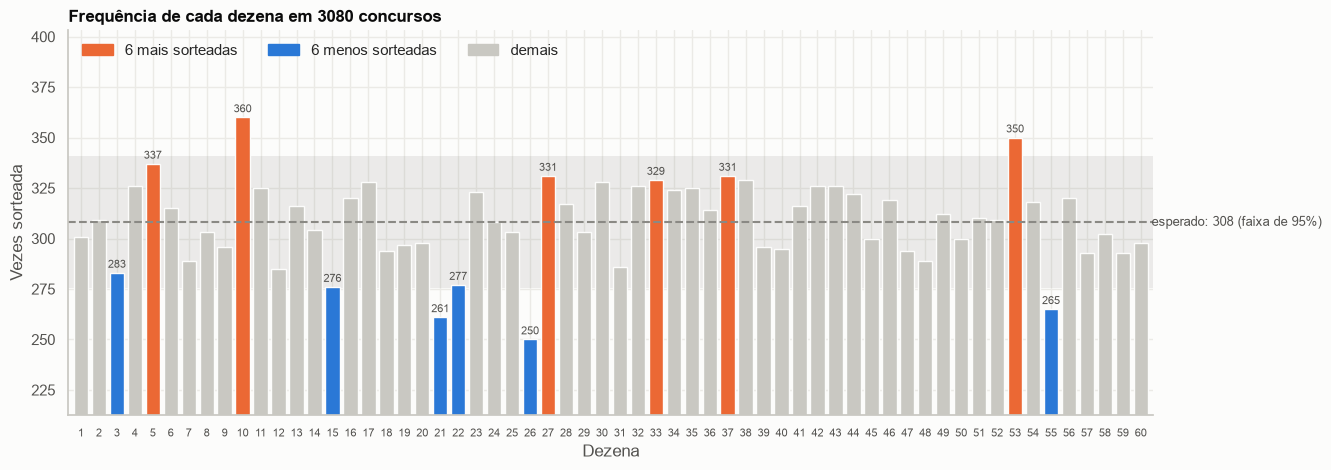

In [6]:
plots.plot_number_frequency(df);

In [7]:
freq = number_frequencies(draws_matrix(df))
expected = len(df) * 6 / 60
ranking = pd.DataFrame({"vezes": freq, "desvio_%": (freq / expected - 1) * 100})
pd.concat([ranking.nlargest(5, "vezes"), ranking.nsmallest(5, "vezes")], keys=["mais", "menos"])

vezes  desvio_%
      dezena                 
mais  10        360   16.8831
      53        350   13.6364
      5         337    9.4156
      27        331    7.4675
      37        331    7.4675
menos 26        250  -18.8312
      21        261  -15.2597
      55        265  -13.9610
      15        276  -10.3896
      22        277  -10.0649

### Frequência acumulada ao longo do tempo

Cada linha é o quanto uma dezena está acima ou abaixo do esperado em cada momento. As "quentes"
de hoje são as que estão no alto agora, mas várias delas passaram longos períodos na média.

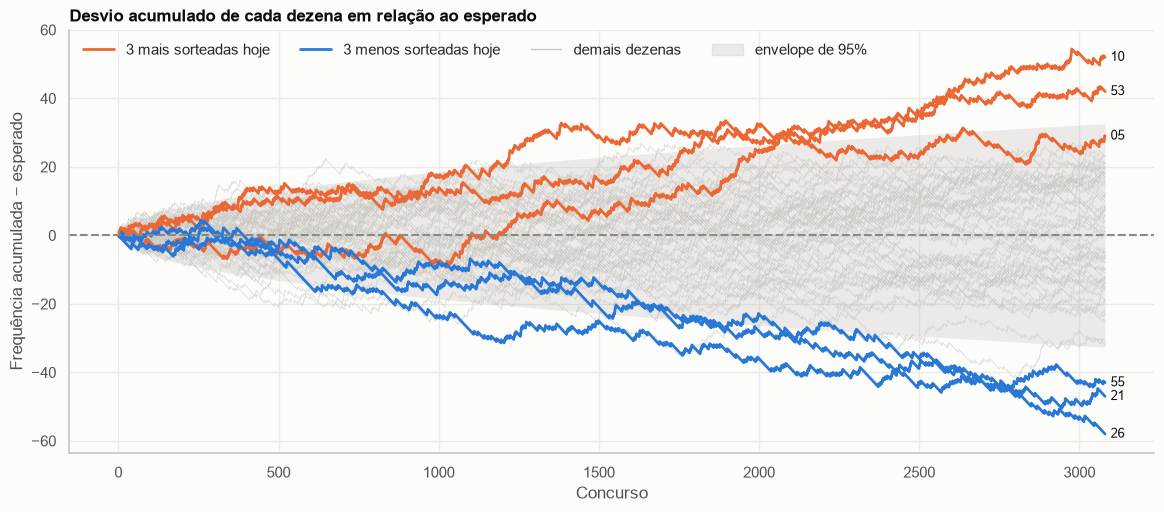

In [8]:
plots.plot_cumulative_frequency(df);

### Pares vs. ímpares

Com 30 pares e 30 ímpares no volante, a teoria (hipergeométrica) prevê 3P/3I em ~33% dos
concursos, e não em 100%: o equilíbrio perfeito é só o resultado mais provável.

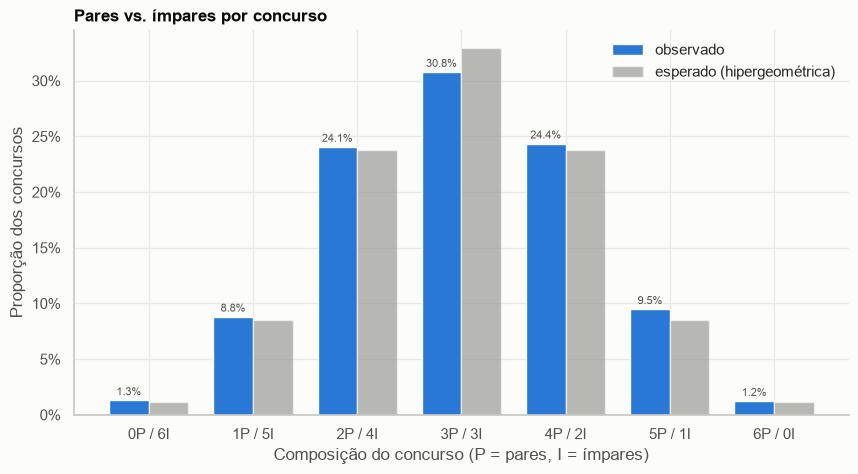

In [9]:
plots.plot_even_odd(df);

### Quadrantes do volante

O volante 6×10 dividido em 4 blocos de 15 dezenas (Q1 superior esquerdo, Q2 superior direito,
Q3 inferior esquerdo, Q4 inferior direito).

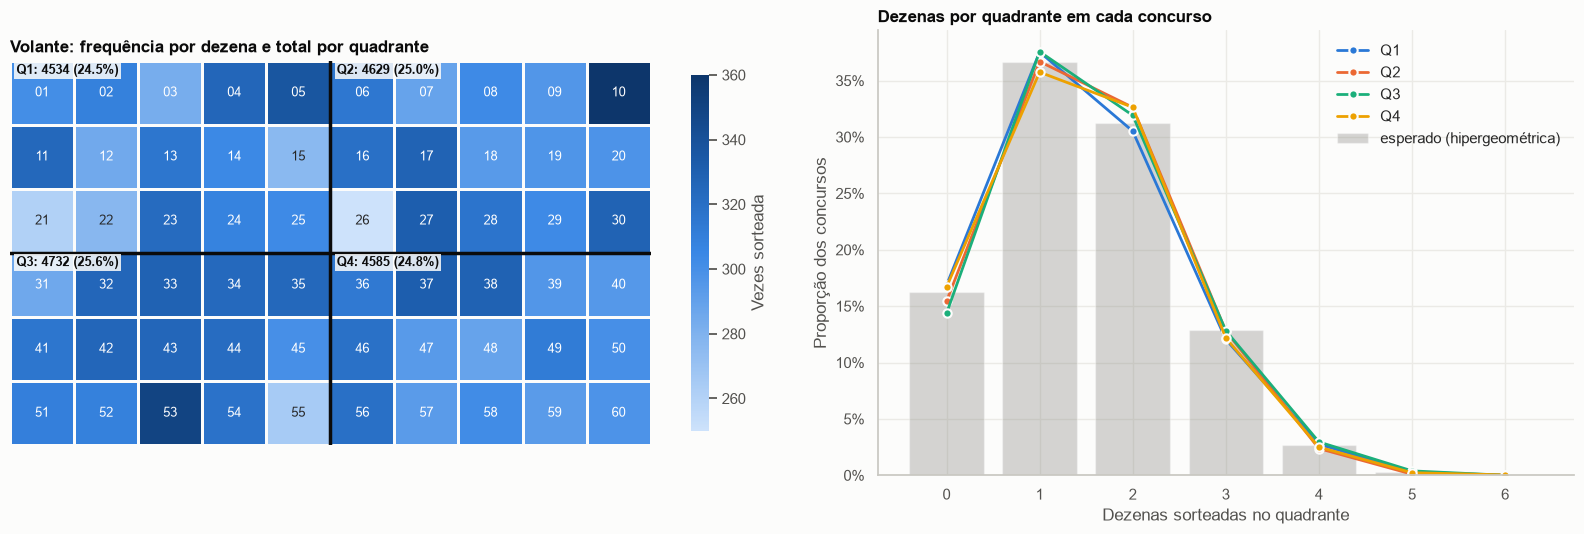

In [10]:
plots.plot_quadrants(df);

## 3. Testes de hipótese

**H0**: cada concurso é uma amostra uniforme de 6 dezenas distintas entre 60, independente dos
anteriores. P-valores baixos (< 0,05) são evidência contra H0.

Os quatro primeiros testes são confirmatórios. As linhas por década são **exploratórias**: as
janelas foram escolhidas depois de ver o resultado global.

In [11]:
tests = run_all_tests(df, n_sims=N_SIMS, seed=SEED)
tests

,teste,estatistica,graus_liberdade,p_valor,observacao
0,Frequência das 60 dezenas,89.0960,59,0.0069,corrigido 54/59
1,Frequência das 60 dezenas (Monte Carlo),81.5455,59,0.0085,estatística sem correção; 2000 simulações
2,Pares por concurso vs. hipergeométrica,8.5872,6,0.1982,7 categorias
3,Total de dezenas por quadrante,5.0245,3,0.1700,corrigido 54/59
4,"Frequência das 60 dezenas, 1996-2005",65.0582,59,0.2741,pós-hoc; 725 concursos
5,"Frequência das 60 dezenas, 2006-2015",68.5732,59,0.1845,pós-hoc; 1050 concursos
6,"Frequência das 60 dezenas, 2016-2026",102.3018,59,0.0004,pós-hoc; 1305 concursos


**Leitura.** A frequência das dezenas rejeita a uniformidade a 1%, e o desvio se concentra na
última década. Pares/ímpares e quadrantes seguem a teoria. A pergunta seguinte é se esse desvio
é **explorável**, ou seja, se dá para ganhar algo apostando nele.

## 4. Backtest

Para cada concurso, cada estratégia aposta 6 dezenas olhando **só** os concursos anteriores.
Sob H0, qualquer aposta acerta em média 0.6 dezena por concurso, seja qual for o
critério. Para saber se uma estratégia se destaca, comparamos a média dela com a de
`N_SIMS` apostadores aleatórios.

In [12]:
strategies = {
    "quentes (histórico)": hot_strategy(),
    f"quentes (últimos {HOT_WINDOW})": hot_strategy(window=HOT_WINDOW),
    "frias (histórico)": cold_strategy(),
    "aleatória": random_strategy,
}
summary, hits, null_means = compare_strategies(
    df, strategies, start=START, n_sims=N_SIMS, seed=SEED, progress=False
)
summary

,estrategia,apostas,media_acertos,quadras,quinas,senas,p_valor_qui2,p_valor_monte_carlo,p_valor_mc_bonferroni
0,quentes (histórico),2980,0.6054,0,0,0,0.8621,0.7036,1.0000
1,quentes (últimos 50),2980,0.6272,1,0,0,0.1888,0.0335,0.1339
2,frias (histórico),2980,0.5725,0,0,0,0.1135,0.0305,0.1219
3,aleatória,2980,0.5916,0,0,0,0.4379,0.5317,1.0000


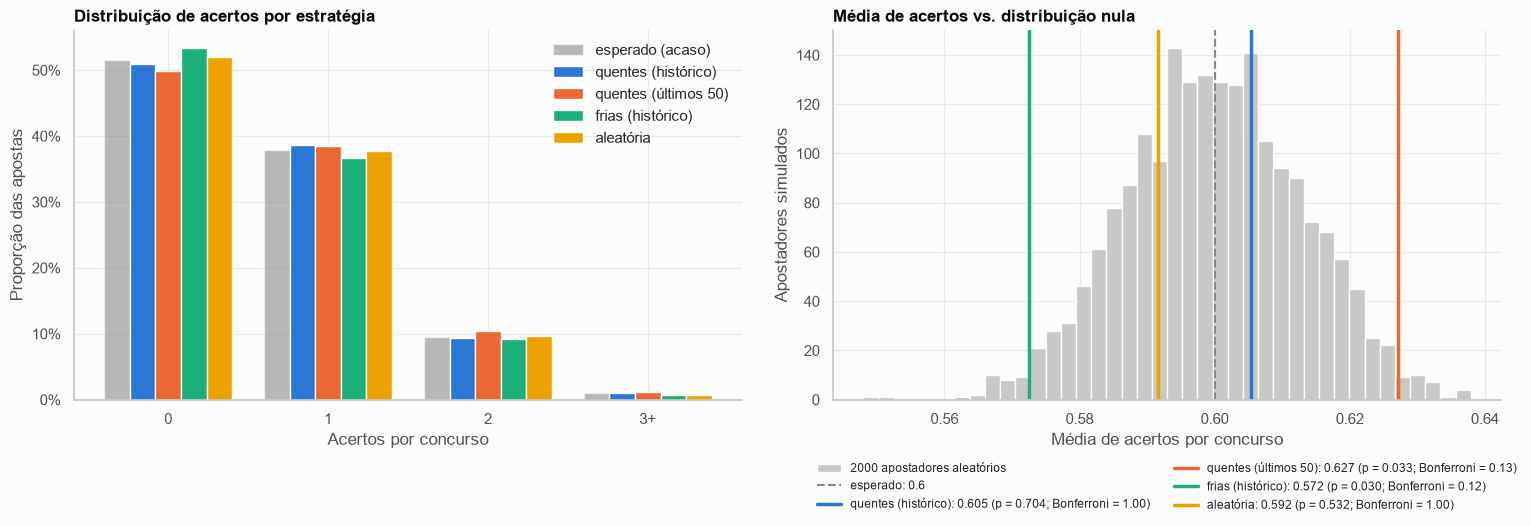

In [13]:
plots.plot_backtest(hits, null_means, summary);

**Leitura.** Nenhuma estratégia sobrevive à correção para múltiplas comparações
(`p_valor_mc_bonferroni`), e as diferenças são de centésimos de acerto por concurso. Uma
frequência estatisticamente desigual não se traduz em vantagem prática.

Experimente mudar `HOT_WINDOW` ou `SEED` na configuração: os p-valores individuais oscilam,
o que mostra como é fácil achar uma estratégia que "funciona" testando variações o bastante.

## Conclusões

- O ETL produz um histórico completo e validado direto da API da Caixa.
- Pares/ímpares e quadrantes seguem exatamente a distribuição prevista pela teoria.
- A frequência das dezenas **não** é perfeitamente uniforme no histórico completo, com o desvio
  concentrado em 2016–2026. Não dá para separar um viés físico de um evento raro do acaso.
- Mesmo assim, nenhuma estratégia baseada no histórico vence o acaso depois da correção para
  múltiplas comparações. Significância estatística não é o mesmo que efeito explorável.